#**ANN in Tensorflow**

In this reading material, you'll learn how to build a simple ANN model, train it using training set,tune different hyperparameter using validation test and finally test our built model. Basically, we will be building basic ANN model in tensorflow  and evaluate it.

##Prerequisites:


1.   Knowledge about commonly used functions in Tensorflow.
2.   Basic workflow of an ANN model.

##Learning Objectives:


1.   Learn about terminologies related to ANN
2.   Learn how to implement a simple ANN in Tensorflow using the Keras API.






## Implementing simple ANN using tensorflow keras


##1.Importing Tensorflow


In [ ]:
import tensorflow as tf

##2. Downloading dataset and Exploring the data
We start by downloading the Fashion MNIST dataset to perform classification.To download it, we use keras.dataset API.



In [ ]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

4423680/4422102 [==============================] - 0s 0us/step


 **Dataset Split ratio :**

 Dataset split normally depends upon two things.First, the total number of samples in  data and second, on the actual model we are training.

 First , we split the data into train set and test set say, $x\%$ data is kept for test set. Remaining $(100-x)\%$ is now split into actual training set and validation set.say $y\%$ is kept for validation set then the final training set becomes $((100-x)-y)\%$ , validation set becomes $y\%$ and test set becomes $x\%$.


Here (x_train, y_train) is our **training dataset**. Training Dataset is an actual dataset that we use to train the model (weights and biases in the case of Neural Network). The model sees and learns from this data. Further split of train set into validation set and train set is done later in the code.

(x_test,y_test) is our **test dataset**. which is the sample of data used to provide an unbiased evaluation of a final model .Our model only sees the test dataset at the end, it is used as final evaluation of the model


Lets check the shape of train and test datasets.


In [ ]:
print(x_train.shape,y_train.shape)
print(x_test.shape,y_test.shape)

(60000, 28, 28) (60000,)
(10000, 28, 28) (10000,)


Here, x_train shape (60000,28,28) means it has 60k examples of image each of size 28*28 and y_train shape (60000,) means it has one label for each 60k training image. Further Exploration of data is done below:


In [ ]:
print(".............1st sample data value...............")
print(".............5x5 pixel patch from 28x28 pixel image sample ...............")
print(x_train[0,10:15,10:15])
# full 28x28 sample image can be viewed from the code below
# print(x_train[0,:,:])
print("...............1st sample label.................")
print(y_train[0])

.............1st sample data value...............
.............5x5 pixel patch from 28x28 pixel image sample ...............
[[  0   0   0 193 228]
 [  3   0  12 219 220]
 [  6   0  99 244 222]
 [  0   0  55 236 228]
 [  0   0 237 226 217]]
...............1st sample label.................
9


##Histogram plot
Now checking total number of label (class) in train dataset and plotting distribution of label in histogram.


......Total number of class is..............
10

.............Class labels are................
tf.Tensor([9 0 3 2 7 5 1 6 4 8], shape=(10,), dtype=uint8)

.............histogram plot of class labels............


(array([6000.,    0., 6000.,    0., 6000.,    0., 6000.,    0., 6000.,
           0.,    0., 6000.,    0., 6000.,    0., 6000.,    0., 6000.,
           0., 6000.]),
 array([0.  , 0.45, 0.9 , 1.35, 1.8 , 2.25, 2.7 , 3.15, 3.6 , 4.05, 4.5 ,
        4.95, 5.4 , 5.85, 6.3 , 6.75, 7.2 , 7.65, 8.1 , 8.55, 9.  ]),
 <a list of 20 Patch objects>)

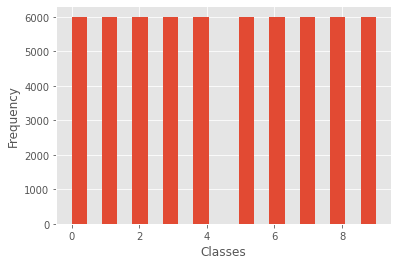

In [ ]:
import matplotlib.pyplot as plt

value,idx = tf.unique(y_train)
print("......Total number of class is..............")
print(len(value))
print("\n.............Class labels are................")
print(value)
print("\n.............histogram plot of class labels............")
plt.style.use('ggplot')
plt.xlabel('Classes')
plt.ylabel('Frequency')
plt.hist(y_train,bins=20)

Now we split training dataset into data for training and validation.
**Validation dataset** is the sample of data used to provide an unbiased evaluation of a model fit on the training dataset while tuning model hyperparameters. Validation dataset is used to tune different hyperparameters so the model is unbiased. A model never learns from the validation dataset.

Here, we use sklearn `train_test_split` api to further split the training dataset.



In [ ]:
from sklearn import model_selection as ms

In [ ]:
x_train,x_val,y_train,y_val= ms.train_test_split(x_train,y_train,test_size=0.2,random_state=42)

In [ ]:
print(x_train.shape,y_train.shape)
print(x_val.shape,y_val.shape)

(48000, 28, 28) (48000,)
(12000, 28, 28) (12000,)


We can see that after the train-validation split,there are 48000 image samples in the final training set that will be used to train the model and 12000 image samples in the validation set that will be used to evaluate the model.


##3. Plotting training examples




In [ ]:
item_list=['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

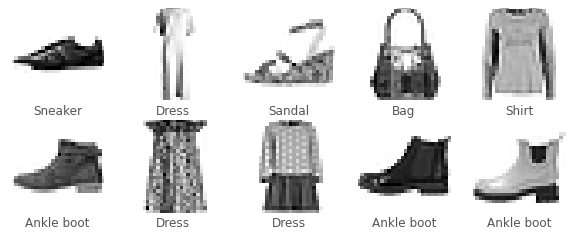

In [ ]:
# plot first few images
plt.figure(figsize=(10,10))
for i in range(10):
  plt.subplot(5,5,i+1)
  plt.xticks([])
  plt.yticks([])
  plt.imshow(x_train[i], cmap=plt.cm.binary)
  plt.xlabel(item_list[y_train[i]])
plt.show() 

Now we have training, validation and test data ready . Our next step is to build an image classification model using ANN.




##Classification using Keras 


We will firstly implement the classification task using keras library. Before building the model, lets us reshape the train, test and validation dataset to make it compatible with the input layer of the model.


In [ ]:
x_train=tf.reshape(x_train,(-1,784))
x_val=tf.reshape(x_val,(-1,784))
x_test=tf.reshape(x_test,(-1,784))

In [ ]:
# let us check the final shapes
print(x_train.shape)
print(y_train.shape)

(48000, 784)
(48000,)


##1. Defining the model parameters


In [ ]:
# the model here will be made of 1 input layer, 3 hidden layers and 1 ouput layer.
input_size=784
output_size=10
hidden_1_shape=128
hidden_2_shape=64
hidden_3_shape=32

##2. Importing necessary functions


In [ ]:
# here we import Sequential where we can add or stack different layers of neural network
# Dense layer implements operation = activation(dot(input,weight)+bias)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Softmax

##3. Using the Sequential API to create the DL model

DL Model is  a trained (or yet to be trained) model which is expected to perform some intelligent stuff. For eg. A diabetes prediction model consist of neural net which can predict whether a person has diabetes when certain features are provided.



In [ ]:
# building model by stacking layers
model=Sequential([
                  Dense(hidden_1_shape,input_shape=(input_size,),activation="sigmoid"),
          
                  Dense(hidden_2_shape,activation="sigmoid"),
                 
                  Dense(hidden_3_shape,activation="sigmoid"),
                
                  Dense(output_size),

                  Softmax()      
])

##4.Selecting Loss Function and Optimizer


In [ ]:
# refer to optimizer and loss function chapter to understand, there are several others too
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [ ]:
model.summary()

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense (Dense)                (None, 128)               100480    
_________________________________________________________________
dense_1 (Dense)              (None, 64)                8256      
_________________________________________________________________
dense_2 (Dense)              (None, 32)                2080      
_________________________________________________________________
dense_3 (Dense)              (None, 10)                330       
_________________________________________________________________
softmax (Softmax)            (None, 10)                0         
Total params: 111,146
Trainable params: 111,146
Non-trainable params: 0
_________________________________________________________________


##5. Initializing Tensorboard and Model Training

 **Hyperparameter Tuning :**
 
 Parameters which define the model architecture are referred to as hyperparameters and thus this process of searching for the ideal model architecture is referred to as hyperparameter tuning.
 
Some basic example of hyperparameters can be :


*   What should be the value of learning rate  for gradient descent?

*   How many trees should I include in my random forest?

*   How many layers should my neural network have?

*   How many neurons should I have in my neural network layer?
etc and many more.


The most important and basic  concept  is that hyperparameters are not model parameters and they cannot be directly trained from the data. Model parameters are learned during training when we optimize a loss function using something like gradient descent.

Here, in the code below you can see that we have used Tensorboard. Tensorboard is a visualization toolkit that can be used to track and visualize metrics like loss and accuracy.




In [ ]:
callbacks = [tf.keras.callbacks.TensorBoard('logs')]

history = model.fit(x_train,y_train,batch_size=128,
          validation_data=(x_val,y_val),epochs=200, callbacks = callbacks)

print(history.history)

Epoch 1/200
  1/375 [..............................] - ETA: 0s - loss: 2.4176 - accuracy: 0.1094WARNING:tensorflow:From /usr/local/lib/python3.6/dist-packages/tensorflow/python/ops/summary_ops_v2.py:1277: stop (from tensorflow.python.eager.profiler) is deprecated and will be removed after 2020-07-01.
Instructions for updating:
use `tf.profiler.experimental.stop` instead.
375/375 [==============================] - 1s 3ms/step - loss: 1.3733 - accuracy: 0.6104 - val_loss: 0.8850 - val_accuracy: 0.7308
Epoch 2/200
375/375 [==============================] - 1s 2ms/step - loss: 0.7909 - accuracy: 0.7297 - val_loss: 0.7565 - val_accuracy: 0.7253
Epoch 3/200
375/375 [==============================] - 1s 2ms/step - loss: 0.7217 - accuracy: 0.7330 - val_loss: 0.7071 - val_accuracy: 0.7352
Epoch 4/200
375/375 [==============================] - 1s 2ms/step - loss: 0.7019 - accuracy: 0.7334 - val_loss: 0.7022 - val_accuracy: 0.7414
Epoch 5/200
375/375 [==============================] - 1s 2ms/step

##6. Visualizing Training Loss and Validation Loss


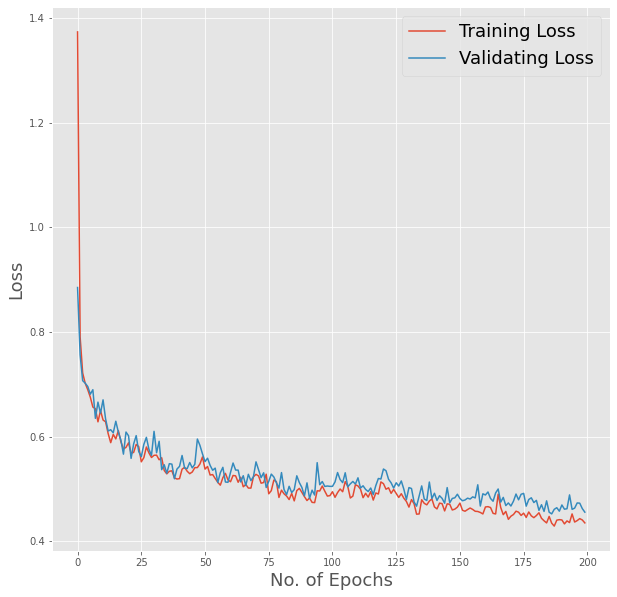

In [ ]:
# to visualize the train and validation loss throughout the process

x = tf.range(0,200)
plt.figure(figsize=(10,10))
plt.plot(x, history.history['loss'], label='Training Loss')
plt.plot(x, history.history['val_loss'], label='Validating Loss')
plt.xlabel('No. of Epochs', fontsize=18)
plt.ylabel('Loss',fontsize=18)
plt.legend(loc='upper right',fontsize=18)



In the plot above, we can see two curves : one for training loss and one validation loss. **Training loss** is the loss calculated on the train set (which includes **both forward and backward propagation**) whereas **validation loss** is calculated on the validation set(which includes only forward propagation of validation data through the model being trained on the train set).


##7.Testing the Model

Now, we use the trained model on our test set to predict class labels.


In [ ]:
loss,accuracy = model.evaluate(x=x_test, y=y_test, batch_size=128,verbose=2)

print('\nTest accuracy:', accuracy)

79/79 - 0s - loss: 0.4771 - accuracy: 0.8312

Test accuracy: 0.8312000036239624


In [ ]:
# predicting value at final layer for each example in the test set
prediction = model.predict(x_test)

In [ ]:
# since we have 10 nodes at final layer and 10000 examples
# sum of value of 10 nodes for each example = 1 , since softmax at final layer
# value at each node is probability of that example to be of that class.
prediction.shape

(10000, 10)

In [ ]:
# choosing class with highest probability
predicted = tf.argmax(prediction,axis=1)

In [ ]:
# since we have 10000 examples 'predicted' has class with highest probability for each
predicted.shape

# let us check the class for out first test sample
print('\n Predicted class for 1st test sample:', predicted[0])
print('\n Actual class for 1st test sample:', y_test[0])


 Predicted class for 1st test sample: tf.Tensor(9, shape=(), dtype=int64)

 Actual class for 1st test sample: 9


##8.Displaying the Predicted Results


In [ ]:
def plot_image(i, predictions_array, true_label, img):
  '''function to plot sample images with 
  actual and predicted labels'''
  predictions_array, true_label, img = predictions_array, true_label[i], img[i]
  plt.grid(False)
  plt.xticks([])
  plt.yticks([])

  plt.imshow(img, cmap=plt.cm.binary)

  # for the image plot, we check if the predicted label is equal to the actual label or not.
  predicted_label = tf.argmax(predictions_array)
  if predicted_label == true_label:
    color = 'blue'
  else:
    color = 'red'

  # we label the images as Predicted class, predicted probability and actual label 
  plt.xlabel("{} {:2.0f}% (Actual:{})".format(item_list[predicted_label],
                                100*tf.reduce_max(predictions_array),
                                item_list[true_label]),
                                color=color,fontsize=18)

def plot_value_array(i, predictions_array, true_label):
  '''function to plot prediction probability for sample images'''
  predictions_array, true_label = predictions_array, true_label[i]
  plt.grid(False)
  plt.xticks(range(10))
  plt.yticks([])
  plt.xlabel('Classes')
  plt.ylabel('Probability')
  thisplot = plt.bar(range(10), predictions_array, color="#777777")
  plt.ylim([0, 1])
  predicted_label = tf.argmax(predictions_array)

  thisplot[predicted_label].set_color('red')
  thisplot[true_label].set_color('blue')

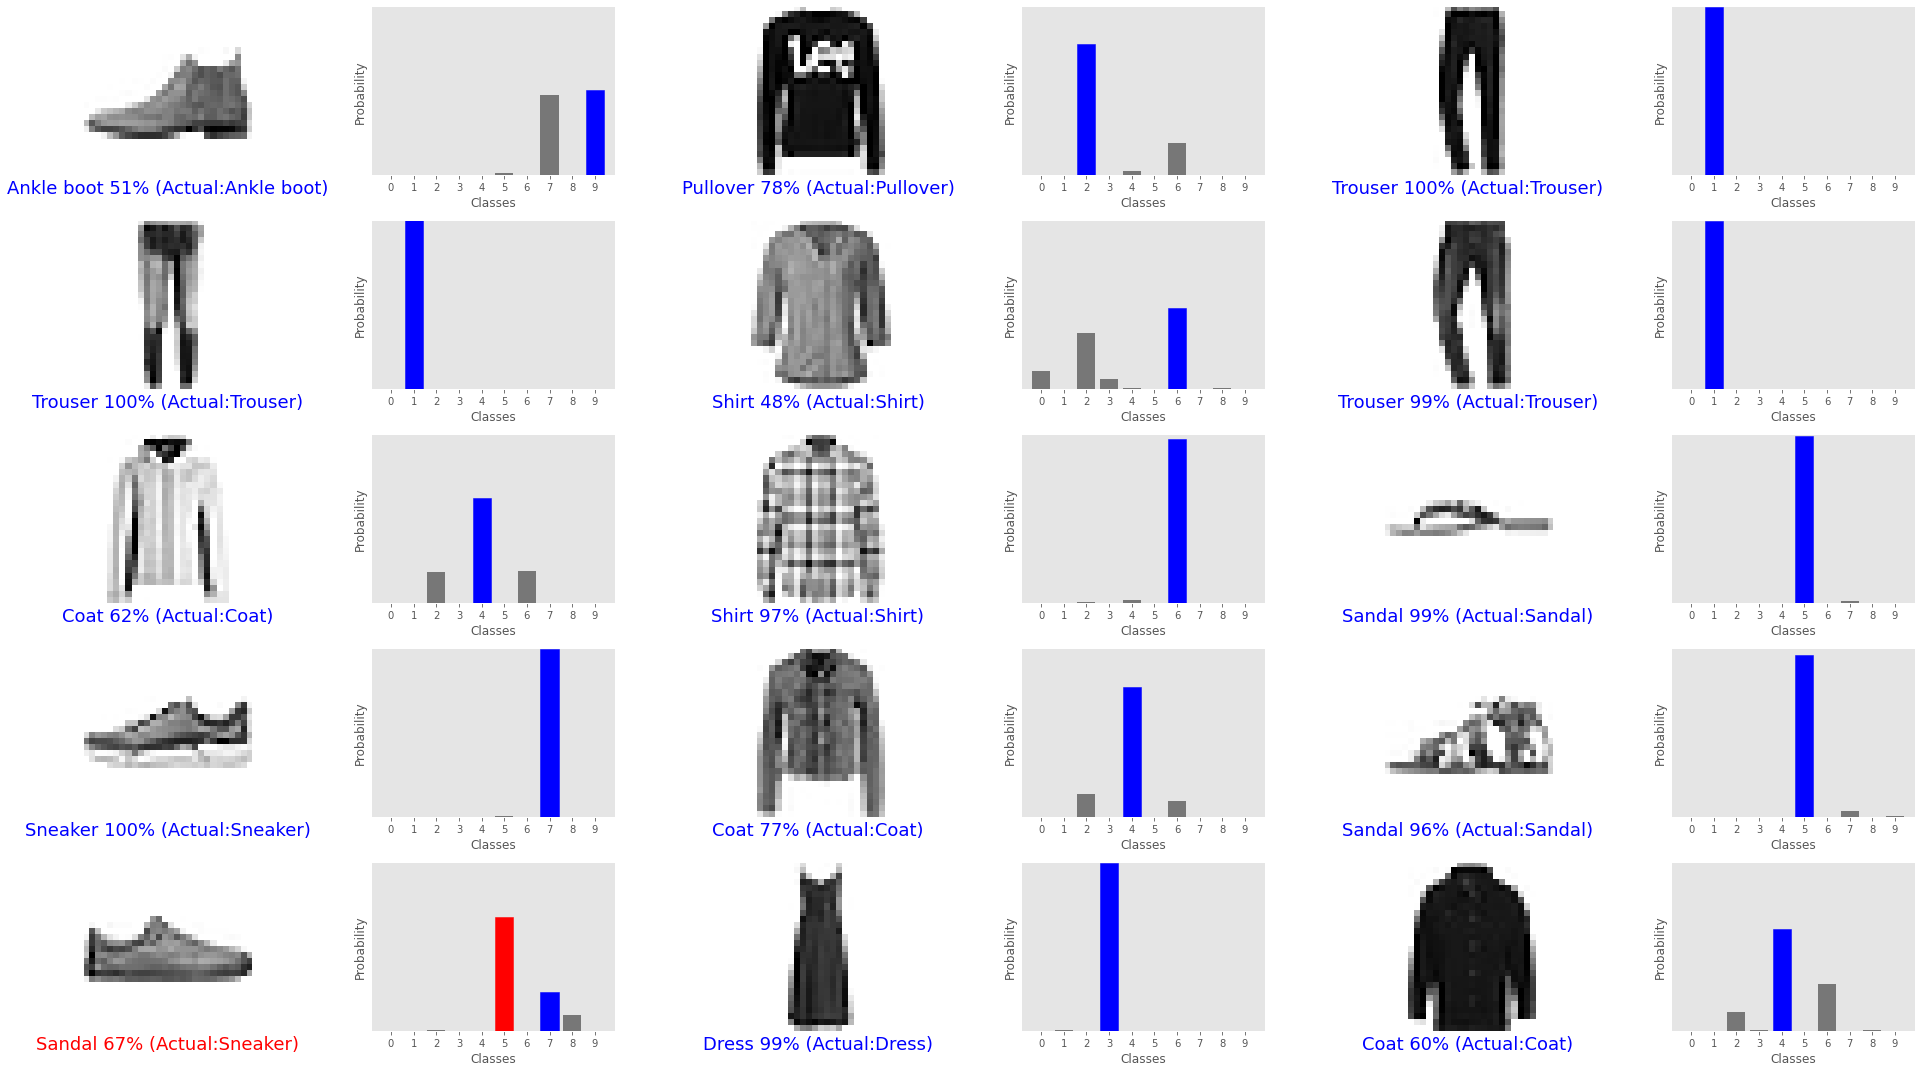

In [ ]:
# We now plot the first X test images, their predicted labels, and the true labels.
# the colors as mentioned above: correct predictions in blue and incorrect predictions in red.

# since we reshaped the test images as well previously, we need to reshape them back 
# to their original shape for the image plot.

x_test=tf.reshape(x_test,(-1,28,28))

num_rows = 5
num_cols = 3
num_images = num_rows*num_cols
plt.figure(figsize=(3*3*num_cols, 3*num_rows))
for i in range(num_images):
  plt.subplot(num_rows, 2*num_cols, 2*i+1)
  plot_image(i, prediction[i], y_test, x_test)
  plt.subplot(num_rows, 2*num_cols, 2*i+2)
  plot_value_array(i, prediction[i], y_test)
plt.tight_layout()
plt.show()

We can see from the above plot and predictions that our model is **not 100% accurate** in its predictions. This is pretty common in machine learning projects and a perfect accuracy score is more of a **theoretical concept**. Surely, our aim should be to obtain as much accuracy as possible and depending on our task it can be other metrics that we might want to improve. Moreover, the metrics scores that we want to settle for will also depend on the area we are planning to apply the model results. Concerns about underfitted and overfitted model may also arise. To put it simply for now, a model is said to be **underfitted when it over simplifies the given problem** and performs badly on both train and test data. On the other hand, an overfitted model is one that **fits to the training data so well that it loses its ability to generalize on the test data**. In the later chapters, we will study about ways to improve our model. But for now, this Deep Learning Pipeline can be a base for building future models.


##Key Takeaways:


1.   The dataset available to us is usually split into train, validation and test set.
2.   Tensorboard can be used as a visualization toolkit.
3. 100% accuracy in DL models is more of a theoretical concept.


